# imports

In [3]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [4]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [5]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

In [6]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_mouse_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-control/src/utils_mouse_control/read_utils.py'>

# setup

In [7]:
ll = 'll00'
data_variant = 'gcamp'

In [8]:
# specific

model_variant = 'ss'
organism = 'mouse'
manual = False
full = False

In [9]:
file_id = 3
save = True

In [10]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename = analysis_utils.read_filename(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

# scores

In [12]:
((bom_spn, _, _, _, _, _, _),
 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_predictions(*metadata)

neuron_scores = analysis_utils.assemble_scoress([bom_spn], [hgm_spn])

In [13]:
# plot_utils.plot_performance_plot(
# 	neuron_scores, None,
# 	title='r2 scores for all neurons', limits=None,
# 	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_all' if save else None
# )

# load

In [14]:
# if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
# 	plot_utils.plot_performance_plot(
# 		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
# 		title='r2 scores for ID\'d neurons', limits=None,
# 		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id' if save else None
# 	)

# shuffle control

In [15]:
shuffles = sum(folder.startswith('shuffle_') for folder in os.listdir(os.path.join(read_utils_control.get_model_path(0), '..'))) - 1

In [16]:
boms_spn, hgms_spn = list(), list()
for shuffle_id in range(shuffles):
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(filename, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	boms_spn.append(bom_spn)
	hgms_spn.append(hgm_spn)

neuron_scores_shuffle = analysis_utils.assemble_scoress(boms_spn, hgms_spn)

In [17]:
percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='bom'
)

percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

percentiles_impr = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='improvement'
)

In [18]:
p_values_sig_bom = ai_slob.percentile_to_p_value_one_sided(percentiles_bom)

p_values_sig_hgm = ai_slob.percentile_to_p_value_one_sided(percentiles_hgm)

p_values_sig_impr = ai_slob.percentile_to_p_value_one_sided(percentiles_impr)

In [19]:
os.makedirs(f'../../out/data/percentiles/{filename}/', exist_ok=True)

pd.DataFrame({key: [val] for key, val in percentiles_hgm.items()}).to_pickle(f'../../out/data/percentiles/{filename}/{model_variant}_hgm.pkl')
pd.DataFrame({key: [val] for key, val in percentiles_impr.items()}).to_pickle(f'../../out/data/percentiles/{filename}/{model_variant}_impr.pkl')

In [20]:
# ai_slob.plot_percentile_hist(percentiles_bom,
# 							 title='BOM r2 percentiles', threshold=100, bins=shuffles,
# 							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_bom_percentiles' if save else None)

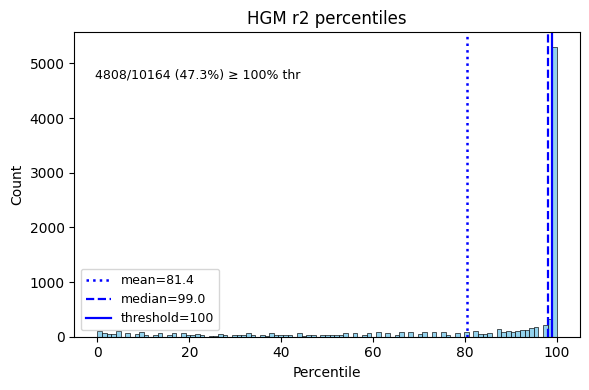

(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'HGM r2 percentiles'}, xlabel='Percentile', ylabel='Count'>)

In [21]:
ai_slob.plot_percentile_hist(percentiles_hgm,
							 title='HGM r2 percentiles', threshold=100, bins=shuffles,
							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_hgm_percentiles' if save else None)

In [22]:
# ai_slob.plot_percentile_hist(percentiles_impr,
# 							 title='HGM r2 improvement percentiles', threshold=100, bins=shuffles,
# 							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_impr_percentiles' if save else None)

In [23]:
neuron_scores_significant = {key: value for key, value in neuron_scores.items() if neuron_scores[key][0] >= 0 and neuron_scores[key][1] >= 0 and percentiles_hgm[key] >= 100.0}
neuron_scores_significant = dict(sorted(neuron_scores_significant.items(), key=lambda x: x[1][1], reverse=True))
neuron_scores_significant = dict(sorted(neuron_scores_significant.items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

In [24]:
if organism == 'worm':
	neuron_scores_significant['AVAR'] = neuron_scores['AVAR']

In [25]:
os.makedirs(f'../../out/data/significant_neurons/{filename}/', exist_ok=True)
pd.DataFrame(neuron_scores_significant).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_hgm.pkl')

In [26]:
# if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
# 	plot_utils.plot_performance_plot_gray(
# 		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()},
# 		neuron_scores_shuffle, {key: neuron_scores_significant[key] for key in neuron_scores_significant.keys() if not key[0].isdigit()}.keys(),
# 		n_label=None,
# 		title='', limits=None,
# 		horizontal_bps=False, vertical_bps=False, force_medians=False, threshold=None,
# 		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_control_id' if save else None
# 	)

In [27]:
# if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
# 	plot_utils.plot_performance_plot(
# 		{key: neuron_scores_significant[key] for key in neuron_scores_significant.keys() if not key[0].isdigit()},
# 		None,
# 		title='r2 scores for ID\'d neurons (+control)', limits=None,
# 		horizontal_bps=False, force_medians=False, threshold=None,
# 	)

# improvement

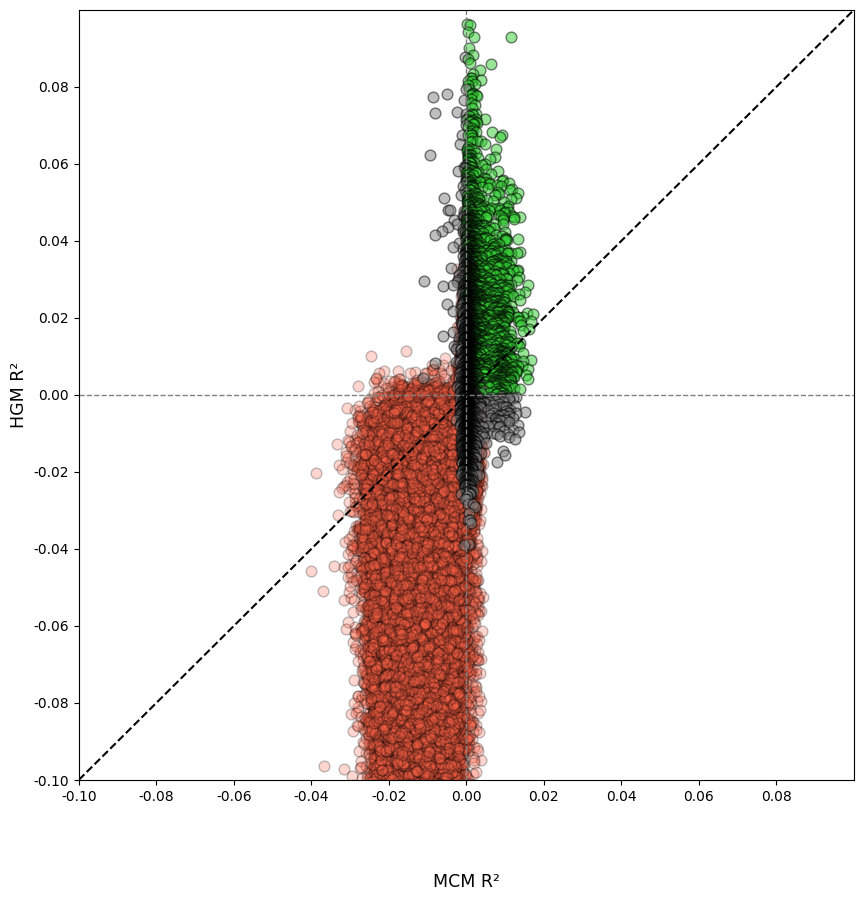

In [28]:
plot_utils.plot_performance_plot_gray(
	neuron_scores, neuron_scores_shuffle, neuron_scores_significant.keys(), n_label=None,
	title='', limits=(-0.1, 0.1, -0.1, 0.1),
	horizontal_bps=False, vertical_bps=False, force_medians=False, threshold=None,
	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_control' if save else None
)

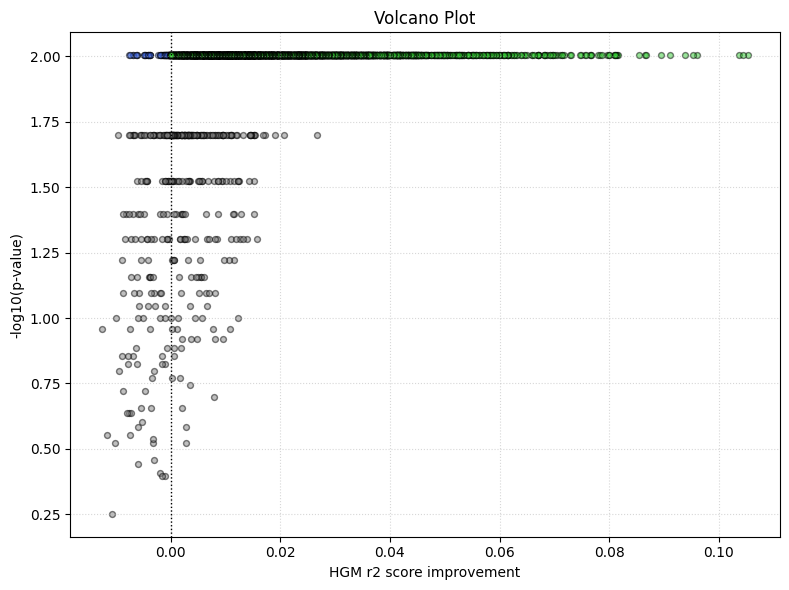

In [29]:
ai_slob.volcano_plot(neuron_scores_significant, p_values_sig_impr, model='improvement', n_label=None, p_thresh=0.0,
					 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_impr_volcano' if save else None)

In [30]:
neuron_scores_significant_impr = {key: value for key, value in neuron_scores_significant.items() if p_values_sig_impr[key] == min(p_values_sig_impr.values())}
neuron_scores_significant_impr = dict(sorted(neuron_scores_significant_impr.items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

pd.DataFrame(neuron_scores_significant_impr).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_impr.pkl')

In [31]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in neuron_scores_significant_impr.keys()])}\'')

'03_9861', '03_4381', '03_2815', '03_5553', '03_7563', '03_6307', '03_7579', '03_7844', '03_6527', '03_1736', '03_7298', '03_4547', '03_9515', '03_5851', '03_6536', '03_1984', '03_2468', '03_8666', '03_7568', '03_9507', '03_6717', '03_7378', '03_5537', '03_1667', '03_7587', '03_2374', '03_6959', '03_8349', '03_5551', '03_7548', '03_7534', '03_3418', '03_6489', '03_8975', '03_7578', '03_5882', '03_4386', '03_7382', '03_6556', '03_6943', '03_4421', '03_9455', '03_4825', '03_5860', '03_2580', '03_4596', '03_3526', '03_8672', '03_2638', '03_6868', '03_7865', '03_4674', '03_8356', '03_5503', '03_8469', '03_6376', '03_5822', '03_7360', '03_8851', '03_6024', '03_4000', '03_8097', '03_726', '03_6803', '03_8852', '03_4427', '03_7755', '03_4629', '03_6799', '03_4592', '03_255', '03_7527', '03_4530', '03_6229', '03_6424', '03_4601', '03_6698', '03_7891', '03_10099', '03_3725', '03_854', '03_2714', '03_1752', '03_8390', '03_3030', '03_115', '03_3078', '03_3666', '03_3426', '03_7333', '03_9482', '0

In [32]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in neuron_scores_significant_impr.keys() if not neuron_label[0].isdigit()])}\'')

''


In [33]:
# importlib.reload(ai_slob)
# ai_slob.plot_control_histograms(neuron_scores, neuron_scores_shuffle, list(neuron_scores.keys())[:100],
# 								model='bom',
# 								save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_neurons' if save else None)
# pass